<a href="https://colab.research.google.com/github/RooBarsic/ITMO/blob/master/Farrukh_Karimov_Copy_of_IR_4_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Задание


Сформулируйте тему итогового задания и соберите данные в корпус.

Постройте граф ключевых (наиболее частотных по корпусу) слов для вашего корпуса.
Для этого необходимо сделать предобработку, включающую токенизацию, лемматизацию, нормализацию и удаление стоп-слова. При построении графа учтите следующие условия:
* ключевым словом может быть только существительное
* ключевое слово не может быть стоп-словом
* между двумя словами есть связь, если они встретились в одном документе;
* вес ребра между вершинами равен количеству документов, в которых два
рассматриваемых слова встретились вместе
* не включайте в граф ребра с весом меньше 2, общее количество вершин
должно быть в диапазоне от 50 до 100
* для визуализации графа можете воспользоваться Gephi или Flourish
* при визуализации настройте размер вершины (по степени) и толщину ребер
(по весу)

Срок сдачи - 2 недели. Первую версию можно не присылать.

## Gephi

Если все же мы имеем дело с огромным графом, где важны все лэйблы вершин, то лучшим средством визуализации на текущий момент является [`Gephi`](https://gephi.org/).

ПО довольно давно разработано и в последние годы не обновляется, но тем не менее обладает достаточным аппаратом для нагляной визуализации графов любого размера. Также возможна кластеризация графа в режиме реального времени.

`Gephi` - декстопный, но free и кроссплатформенный.

Графы из предыдущего примера с помощью `Gephi` можно представить в следующем виде.

Эго-граф ключевых слов для вершины `Digital Humanities`.
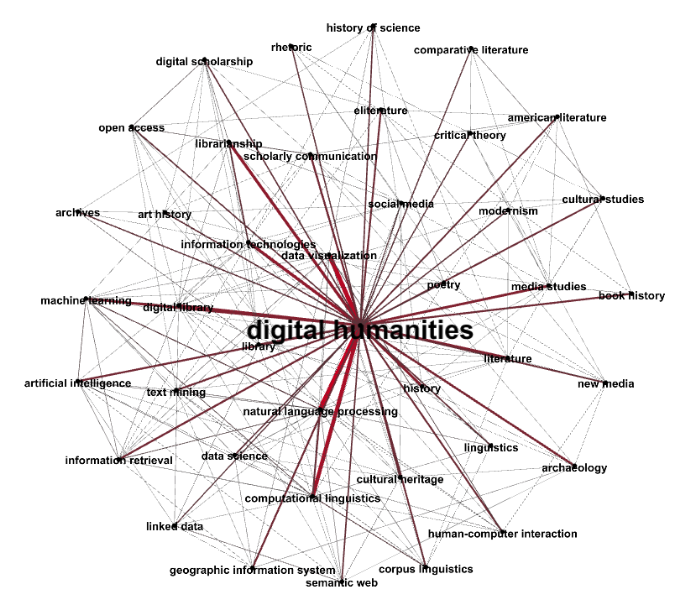

Граф ключевых слов без вершины `Digital Humanities`.
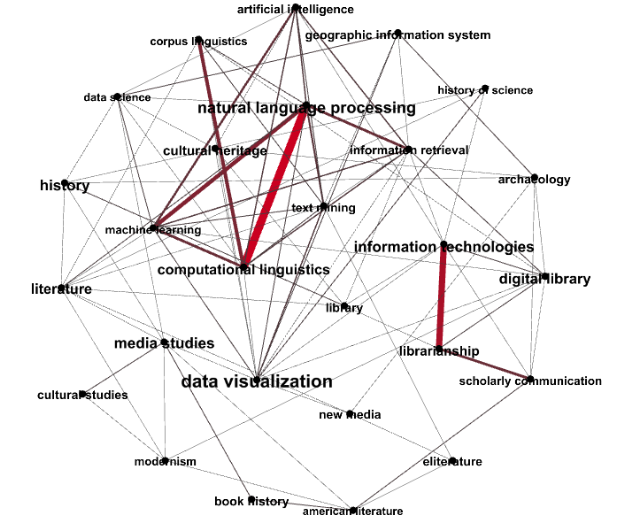

Пример визуализации одного кластера.
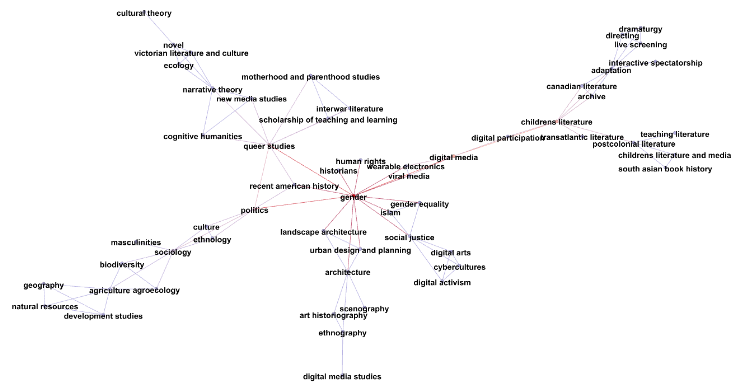

Граф подобластей `Digital Humanities`.
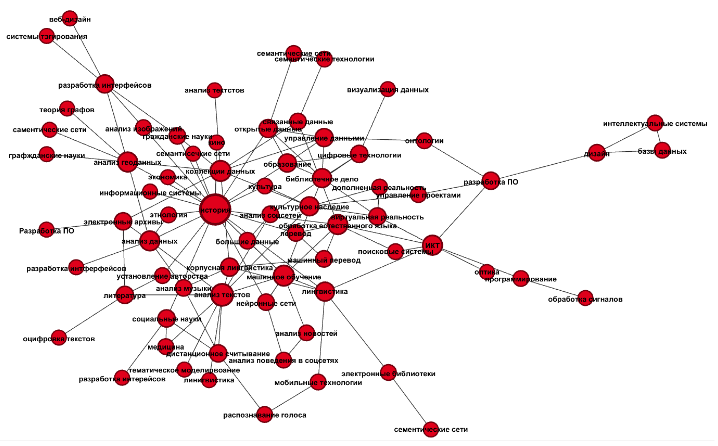

При желании подробнее про эту задачу можно почитать в [статье](http://ceur-ws.org/Vol-2813/rpaper12.pdf).

Есть еще прикольная штука для визуализации объемных текстов в виде графа - [News Graph](https://github.com/BrambleXu/news-graph).

# Решение

Возьмём сайт codeforces.com в каотором есть множество публикаций связанных с ИТ и спортивным программированием. http://codeforces.com/page/2

Всего страниц с публикациями - 198. На каждой странице около 10-ти постов на русском и наглийском языках.

Сделаем необходимые импорты

In [ ]:
from urllib.request import urlopen
import nltk
from nltk.tokenize import word_tokenize # готовый токенизатор библиотеки nltk
from nltk import tokenize
from nltk import ngrams
from nltk.tokenize import sent_tokenize
import matplotlib.pyplot as plt
from urllib.request import urlopen
import nltk
from nltk.tokenize import word_tokenize # готовый токенизатор библиотеки nltk
from nltk import tokenize
from nltk import ngrams
from nltk.tokenize import sent_tokenize
! pip install rusenttokenize
from rusenttokenize import ru_sent_tokenize
from bs4 import BeautifulSoup as bs
import requests

nltk.download('stopwords')
nltk.download('punkt')

nltk.download('stopwords')
nltk.download('punkt')

import plotly
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as pximport
# !pip uninstall matplotlib
# !pip install matplotlib==3.1.0

from bs4 import NavigableString

import string


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


Функция для получения русскоязычной ссылки на страницу по номеру страницы

In [ ]:
def getPageUrl(page_id):
  MAIN_RESOURCE_URL_PREFIX = "http://codeforces.com/"
  PAGE_KEY_WORD = "page/"
  LAGNUAGE_PREFERENCES = "?locale=ru"
  return MAIN_RESOURCE_URL_PREFIX + PAGE_KEY_WORD + str(page_id) + LAGNUAGE_PREFERENCES


Функция для извлечения ссылок на все русскоязычные посты из страницы


In [ ]:
def getRussianPostsLinksFomPage(page_url):
  MAIN_RESOURCE_URL_PREFIX = "http://codeforces.com"
  RUSSIAN_POST_IDENTIFIER = "По-русски"
  page = requests.get(page_url)
  soup = bs(page.text, "html.parser")
  topics = soup.findAll("div", {"class": "topic"})

  posts_urls = []
  for topic in topics:
    title = topic.findAll("div", {"class": "title"})[0]
    url_syffix = title.findAll("a")[0].attrs['href']

    info = topic.findAll("div", {"class": "info"})[0]
    language = info.findAll("img")[0].attrs['alt']
    # print(url_syffix, " ", language)

    if language == RUSSIAN_POST_IDENTIFIER:
      posts_urls.append(MAIN_RESOURCE_URL_PREFIX + url_syffix)

  # posts_urls_syffix = [div.findAll("a")[0] for div in result]
  # posts_urls_syffix = [a.attrs['href'] for a in posts_urls_syffix]
  # posts_urls = [MAIN_RESOURCE_URL_PREFIX + syffix for syffix in posts_urls_syffix]

  return posts_urls


Функцию для извлечения текста постов по ссылке на пост

In [ ]:
def getTextFromPost(post_url):
  page = requests.get(post_url)
  soup = bs(page.text, "html.parser")

  topics = soup.findAll("div", {"class": "ttypography"})

  topic_text = topics[0].text

  return topic_text

Сгенерируем ссылки на все страницы. Всего 198 страниц.

In [ ]:
pages_number = 198

pages_urls = [getPageUrl(i) for i in range(1, 199)]

len(pages_urls)

198

Извлечём ссылки всех русско язычных постов из стрпниц.

In [ ]:
ru_posts_urls = [getRussianPostsLinksFomPage(page) for page in pages_urls]

print("Количество обработанных страниц : ", len(ru_posts_urls))

Количество обработанных страниц :  198


Получили ссылки русскоязычных постов из всех 198 страниц с постами. Теперь объеденим все ответы в одну.

In [ ]:
posts_urls = sum(ru_posts_urls, [])

print("Количество русскоязычных постов : ", len(posts_urls))
posts_urls[:5]

Количество русскоязычных постов :  1541


['http://codeforces.com/blog/entry/101708',
 'http://codeforces.com/blog/entry/101397',
 'http://codeforces.com/blog/entry/101079',
 'http://codeforces.com/blog/entry/100277',
 'http://codeforces.com/blog/entry/100808']

Добавим к ссылке на каждый пост - суффикс для обозначения языка контента

In [ ]:
posts_urls = [post_url + "?locale=ru" for post_url in posts_urls]
posts_urls[:5]

['http://codeforces.com/blog/entry/101708?locale=ru',
 'http://codeforces.com/blog/entry/101397?locale=ru',
 'http://codeforces.com/blog/entry/101079?locale=ru',
 'http://codeforces.com/blog/entry/100277?locale=ru',
 'http://codeforces.com/blog/entry/100808?locale=ru']

Для каждого поста - извлечём его текст.

In [ ]:
pp = posts_urls[:5]

posts_texts = [getTextFromPost(post_url) for post_url in posts_urls]

for post_text in posts_texts:
  print(len(post_text))

1136
1975
1154
1117
864
1284
1159
1954
1312
2340
3189
1276
2559
1487
1685
7920
2142
896
1150
8537
1155
1044
1310
967
2079
1113
1714
1178
2258
2243
1569
1969
3635
787
1178
2731
2217
992
1932
1416
3805
1973
2309
1179
4239
2332
1213
1352
3891
3793
1904
2519
2870
5041
2278
4820
1759
1588
3334
2170
2328
1952
2833
1889
2852
1516
3011
2082
1412
2639
1932
3357
2808
1319
1536
2534
1120
3719
1339
816
816
4037
1847
2999
672
1807
2004
1306
3152
896
2542
2231
1321
1198
3618
1614
1367
1939
59
1821
3295
885
1426
2142
1791
1044
2051
890
2954
1248
1406
1501
2006
1786
1512
4261
2541
1820
1846
1542
1390
2534
4552
735
3828
1750
4049
4246
1943
1241
2530
1780
568
1576
1627
1180
1572
1596
4106
1545
1602
1945
2282
983
1815
1227
789
5178
1911
2247
1251
1600
1110
2078
1618
813
1309
2056
890
1777
1755
1225
862
1250
1973
845
2835
1095
1936
1450
1983
1821
3523
1148
2116
1786
569
3189
1890
2221
2987
655
3047
1698
2500
1990
3053
1996
2728
2034
1975
723
1196
1964
4132
893
1020
844
1948
1780
957
1943
2360
1742
2219
29

Чтобы использовать токенизатор word_tokenize, нужно сначала скачать данные для nltk о пунктуации и стоп-словах.

In [ ]:
nltk.download('stopwords')
nltk.download('punkt')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

Загрузим список стопслов в русском языке

In [ ]:
from nltk.corpus import stopwords
stop_words_ru = stopwords.words('russian')
print(stop_words_ru)

['и', 'в', 'во', 'не', 'что', 'он', 'на', 'я', 'с', 'со', 'как', 'а', 'то', 'все', 'она', 'так', 'его', 'но', 'да', 'ты', 'к', 'у', 'же', 'вы', 'за', 'бы', 'по', 'только', 'ее', 'мне', 'было', 'вот', 'от', 'меня', 'еще', 'нет', 'о', 'из', 'ему', 'теперь', 'когда', 'даже', 'ну', 'вдруг', 'ли', 'если', 'уже', 'или', 'ни', 'быть', 'был', 'него', 'до', 'вас', 'нибудь', 'опять', 'уж', 'вам', 'ведь', 'там', 'потом', 'себя', 'ничего', 'ей', 'может', 'они', 'тут', 'где', 'есть', 'надо', 'ней', 'для', 'мы', 'тебя', 'их', 'чем', 'была', 'сам', 'чтоб', 'без', 'будто', 'чего', 'раз', 'тоже', 'себе', 'под', 'будет', 'ж', 'тогда', 'кто', 'этот', 'того', 'потому', 'этого', 'какой', 'совсем', 'ним', 'здесь', 'этом', 'один', 'почти', 'мой', 'тем', 'чтобы', 'нее', 'сейчас', 'были', 'куда', 'зачем', 'всех', 'никогда', 'можно', 'при', 'наконец', 'два', 'об', 'другой', 'хоть', 'после', 'над', 'больше', 'тот', 'через', 'эти', 'нас', 'про', 'всего', 'них', 'какая', 'много', 'разве', 'три', 'эту', 'моя', 'впр

Загрузим библиотеку для лемматизации слов


In [ ]:
!pip install pymorphy2
from pymorphy2 import MorphAnalyzer
pymorphy2_analyzer = MorphAnalyzer()

Напишем функцию которая сделает токенизацию, очистку пунктуаций, преобразование регистра для заданного текста

In [ ]:
def processText(text):
  # сделаем токенизацию
  tokens = text.split('.')
  tokens = [word_tokenize(text_i) for text_i in tokens]
  tokens = sum(tokens, [])
  # print("post len = ", len(text), " tokens len = ", len(tokens))

  # сделаем нормализацию
  #удалим символы пунктуации
  clean_tokens = [token.strip(string.punctuation) for token in tokens]

  ### удалим пустрые токены
  clean_tokens = list(filter(None, clean_tokens))

  ### удалим цифры
  chars = set('0123456789$,—')
  clean_tokens = [token for token in clean_tokens if not any((c in chars) for c in token)]

  ### приведём все слова к нижнему регистру
  clean_tokens = [token.lower() for token in clean_tokens if token != '']

  # сделаем лемматизацию слов
  clean_tokens = [ pymorphy2_analyzer.parse(token)[0] for token in clean_tokens]
  clean_tokens = [ data for data in clean_tokens if data.tag.POS == 'NOUN']
  clean_tokens = [ data.normal_form for data in clean_tokens]

  # удалим стоп слова
  clean_tokens = [token for token in clean_tokens if token not in stop_words_ru]
  # print("post len = ", len(text), " tokens len = ", len(clean_tokens))

  # print()

  return clean_tokens

Сделаем токенизацию для каждого поста

In [ ]:
posts_tokens = [processText(post) for post in posts_texts]
posts_tokens[0]


['привет',
 'время',
 'серия',
 'раунд',
 'рамка',
 'инициатива',
 'подробность',
 'сотрудничество',
 'пост',
 'раунд',
 'участник',
 'рейтинг',
 'соревнование',
 'правило',
 'штраф',
 'посылка',
 'посылка',
 'решение',
 'минута',
 'окончание',
 'раунд',
 'период',
 'время',
 'длительность',
 'час',
 'течение',
 'решение',
 'число',
 'код',
 'чтение',
 'копирование',
 'задача',
 'час',
 'задача',
 'адилбек',
 'далабай',
 'владимир',
 'петров',
 'иван',
 'андрос',
 'максим',
 'мещеряк',
 'михаил',
 'мирзаянов',
 'система',
 'удача',
 'раунд',
 'решение']

**Выделение ключевых слов**

Так как тот фак - что одна и таже пара слов встретилась в посте несколько раз - никак не повлияет на итоговое отображение этой пары слов, то давайте оставим только уникальные токены для каждого поста

In [ ]:
print("Количество токенов в первом посте до уникализации : ", len(posts_tokens[0]))
posts_tokens = [list(set(post_tokens)) for post_tokens in posts_tokens]
print("Количество токенов в первом посте после уникализации : ", len(posts_tokens[0]))


Количество токенов в первом посте до уникализации :  48
Количество токенов в первом посте после уникализации :  39


Посчитаем количество уникальных слов

In [ ]:

uniq_words_frequency = {}

for post_tokens in posts_tokens:
  for token in post_tokens:
    if token in uniq_words_frequency:
      uniq_words_frequency[token] = uniq_words_frequency[token] + 1
    else :
      uniq_words_frequency[token] = 1

uniq_words = uniq_words_frequency.keys()
uniq_words = [(word, uniq_words_frequency[word]) for word in uniq_words]
uniq_words = sorted(uniq_words, key=lambda x: x[1], reverse=True)

print("Количество уникальных слов : ", len(uniq_words))

uniq_words[:20]


Количество уникальных слов :  6648


[('задача', 1253),
 ('участник', 1045),
 ('раунд', 1012),
 ('время', 925),
 ('привет', 844),
 ('соревнование', 801),
 ('решение', 729),
 ('удача', 703),
 ('разбор', 679),
 ('участие', 677),
 ('час', 658),
 ('победитель', 576),
 ('контест', 565),
 ('подготовка', 513),
 ('помощь', 493),
 ('год', 493),
 ('рейтинг', 490),
 ('результат', 489),
 ('условие', 481),
 ('команда', 470)]

**Построение графа**

In [ ]:
print('Всего уникальных слов : ', len(uniq_words))

Всего уникальных слов :  6648


Пусть в качестве вершин графа - возьмём топ 70 наиболее встречающихся слов

In [ ]:
graph_nodes = []
for word in uniq_words[:70]:
  graph_nodes.append(word[0])
graph_nodes

['задача',
 'участник',
 'раунд',
 'время',
 'привет',
 'соревнование',
 'решение',
 'удача',
 'разбор',
 'участие',
 'час',
 'победитель',
 'контест',
 'подготовка',
 'помощь',
 'год',
 'рейтинг',
 'результат',
 'условие',
 'команда',
 'дивизион',
 'система',
 'правило',
 'михаил',
 'программирование',
 'день',
 'число',
 'место',
 'ссылка',
 'тестирование',
 'окончание',
 'автор',
 'язык',
 'человек',
 'минута',
 'разбалловка',
 'конкурс',
 'начало',
 'взлом',
 'внимание',
 'мирзаянов',
 'олимпиада',
 'финал',
 'пост',
 'работа',
 'возможность',
 'код',
 'перевод',
 'платформа',
 'чемпионат',
 'тест',
 'регистрация',
 'образ',
 'количество',
 'сложность',
 'сайт',
 'случай',
 'школьник',
 'университет',
 'иван',
 'этап',
 'таблица',
 'балл',
 'программа',
 'друг',
 'течение',
 'проведение',
 'белов',
 'максим',
 'идея']

Давайте для каждого выбранного слова - сделаем битмаску длиной в количество имеющихся документов. 1 - будет означать что слово встречается в документе, а 0 - что слово отсуцтвует в документе.

Вспомогательные функции для работы с масками

In [ ]:
def createMask(mask_size, defaul_value):
  mask = []
  for i in range(0, mask_size):
    mask.append(defaul_value)
  return mask

def bitAndMasks(mask_a, mask_b, len):
  result_mask = []
  for i in range(0, len):
    if mask_a[i] == True and mask_b[i] == True:
      result_mask.append(True)
    else :
      result_mask.append(False)
  return result_mask

def countMaskPositiveBits(mask, len):
  positiveBits = 0
  for bit in mask:
    if bit == True:
      positiveBits = positiveBits + 1
  return positiveBits

In [ ]:
nodes_mask = {}

for node in graph_nodes:
  nodes_mask[node] = createMask(len(posts_tokens), False)


In [ ]:
for i in range(0, len(posts_tokens)):
  post_tokens = posts_tokens[i]
  for node in graph_nodes:
    if node in post_tokens:
      nodes_mask[node][i] = True

for node in graph_nodes[:10]:
  print(node, nodes_mask[node])

задача [True, True, True, True, False, True, True, True, True, True, False, True, True, False, True, True, True, False, True, True, False, False, True, True, True, True, True, True, True, True, False, True, True, False, True, True, True, False, True, True, True, True, True, True, False, True, True, False, True, True, True, True, False, True, True, False, True, True, True, True, True, True, True, True, False, True, True, True, True, True, True, True, True, True, False, True, False, True, True, True, False, True, True, True, True, True, False, True, True, True, True, False, True, True, True, True, False, True, False, True, True, True, False, False, True, False, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, False, True, True, True, True, True, True, True, True, True, True, True, False, False, True, True, True, True, True, False, True, True, False, True, True, False, False, True, True, True, True, True, True, True, False, True, True, True, True, 

Давайте определимся с рёбрами.

Каждое ребро нашего графа - соответствует трём условиям :
1. ребро - это связь меду двумя словами
2. если два слова встречаются в одном посте, то между ними будет ребро
3. вес ребра - это количество постов в котороых эти слова встретились

Так как для каждого из выбранных слов мы составили битмаску появления слова в посте, то для того чтобы определить факт сушествования ребра между двумя словами A и B, а также вес этого ребра, если он существует - нам достаточно сделать побитовое and для битовых маско слов A и B. При этом вес ребра будет количестов 1 в результирующей маске.

In [ ]:
graph_edges = []

for i in range(0, len(graph_nodes)):
  node_a = graph_nodes[i]
  mask_a = nodes_mask[node_a]
  for j in range(i + 1, len(graph_nodes)):
    node_b = graph_nodes[j]
    mask_b = nodes_mask[node_b]

    edge_mask = bitAndMasks(mask_a, mask_b, len(mask_a))
    edge_weight = countMaskPositiveBits(edge_mask, len(edge_mask))

    if edge_weight >= 2:
      graph_edges.append((i, j, edge_weight))

graph_edges[:6]

[(0, 1, 915), (0, 2, 933), (0, 3, 821), (0, 4, 741), (0, 5, 718), (0, 6, 709)]

Завернём данные о вершинах в DataFrame

In [ ]:
nodes = pd.DataFrame(list(zip(graph_nodes)), columns = ['Label'])
nodes.head()

,Label
0,задача
1,участник
2,раунд
3,время
4,привет


Завернём данные о рёбрах в DataFrame

In [ ]:
start_edges = [edge[0] for edge in graph_edges]
end_edges = [edge[1] for edge in graph_edges]
weight_edges = [edge[2] for edge in graph_edges]
types_edges = ['Undirected' for edge in graph_edges]

edges = pd.DataFrame(list(zip(start_edges, end_edges, types_edges, weight_edges)), columns = ['Source', 'Target', 'Type', 'Weight'])
edges

,Source,Target,Type,Weight
0,0,1,Undirected,915
1,0,2,Undirected,933
2,0,3,Undirected,821
3,0,4,Undirected,741
4,0,5,Undirected,718
...,...,...,...,...
2410,66,68,Undirected,10
2411,66,69,Undirected,34
2412,67,68,Undirected,33
2413,67,69,Undirected,21


In [ ]:
from google.colab import files

nodes.to_csv('nodes.csv', encoding = 'utf-8-sig')
files.download('nodes.csv')

edges.to_csv('edges.csv', encoding = 'utf-8-sig')
files.download('edges.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
nodes.head()

,Label
0,задача
1,участник
2,раунд
3,время
4,привет


**Граф для топ 70 слов**

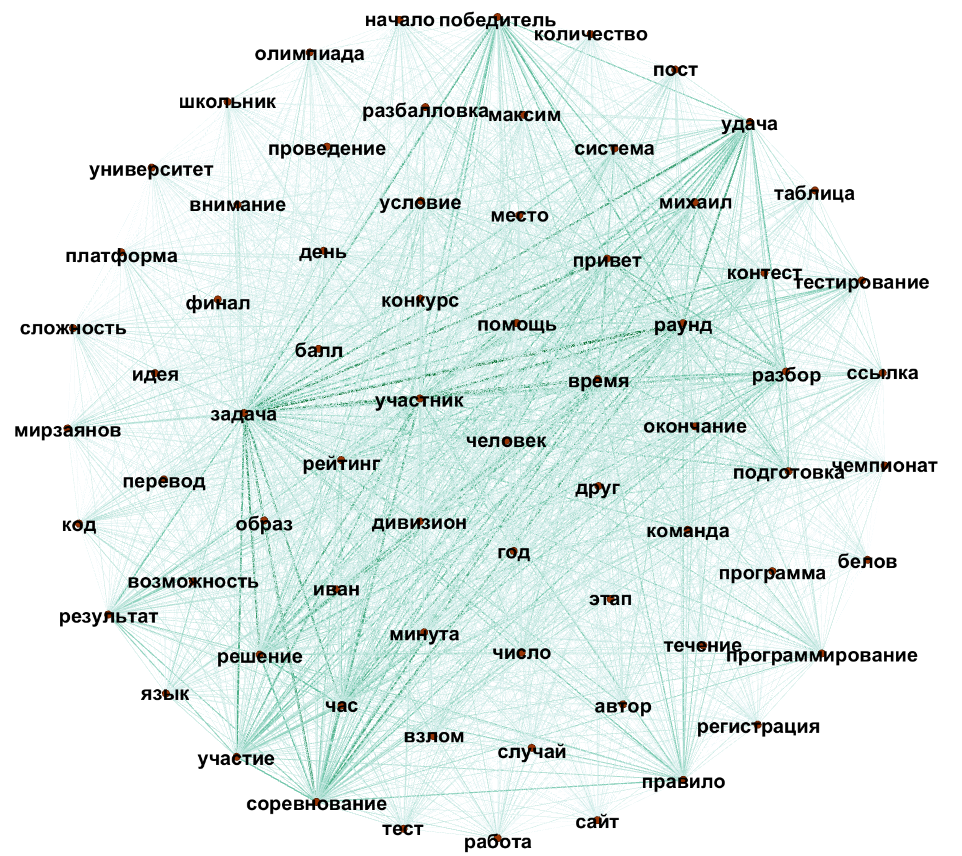

Теперь для интереса попробуем построить такой же граф - для топ 30 слов

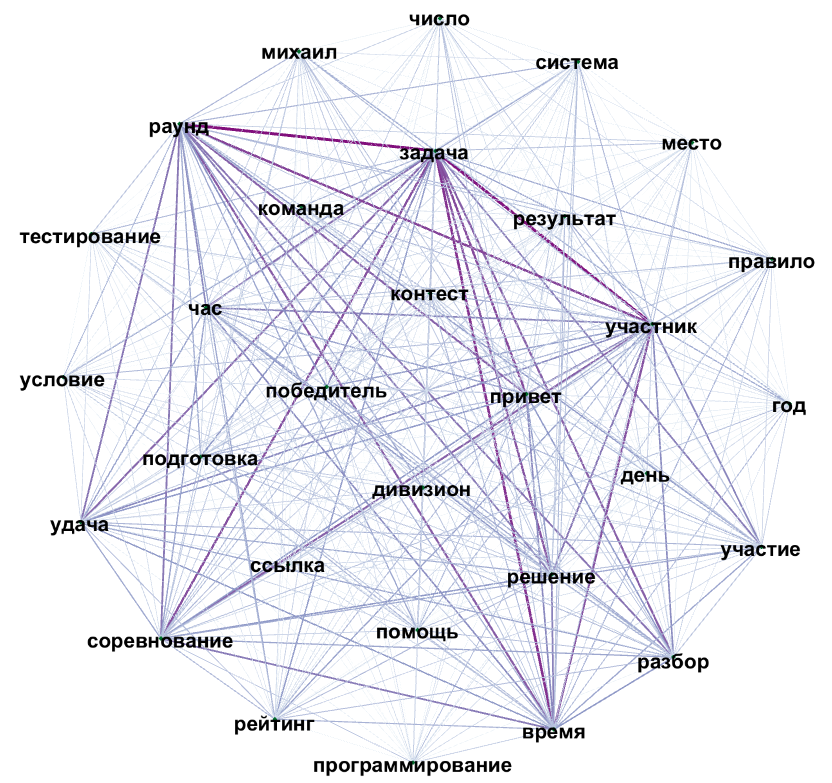

Каждое ребро нашего графа - соответствует трём условиям :

1. ребро - это связь меду двумя словами
2. если два слова встречаются в одном посте, то между ними будет ребро
3. вес ребра - это количество постов в котороых эти слова встретились


**Черновики**

In [ ]:
#
# Черновик № 1
#




#Для тестирования и создания одтельных функций для получения нужных данных по ссылке

from urllib.request import urlopen
import nltk
from nltk.tokenize import word_tokenize # готовый токенизатор библиотеки nltk
from nltk import tokenize
from nltk import ngrams
from nltk.tokenize import sent_tokenize
! pip install rusenttokenize
from rusenttokenize import ru_sent_tokenize
from bs4 import BeautifulSoup as bs
import requests

nltk.download('stopwords')
nltk.download('punkt')

from bs4 import NavigableString

def getPostLinksByPageLink(page_url):
  page = requests.get(page_url)
  soup = bs(page.text, "html.parser")
  print(soup)



def getTextFromPost(post_url):
  page = requests.get(post_url)
  soup = bs(page.text, "html.parser")

  topics = soup.findAll("div", {"class": "ttypography"})[0]

  print(topics)

  # topic_text = topics[0]

  # print(topic_text)

  # return topic_text


getTextFromPost("http://codeforces.com/blog/entry/101708?locale=ru")

# getPostLinksByPageLink("http://codeforces.com/page/1?locale=ru")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [ ]:
#
# Черновик № 2
#





#Для тестирования и создания одтельных функций для получения нужных данных по ссылке

from urllib.request import urlopen
import nltk
from nltk.tokenize import word_tokenize # готовый токенизатор библиотеки nltk
from nltk import tokenize
from nltk import ngrams
from nltk.tokenize import sent_tokenize
! pip install rusenttokenize
from rusenttokenize import ru_sent_tokenize
from bs4 import BeautifulSoup as bs
import requests

nltk.download('stopwords')
nltk.download('punkt')

from bs4 import NavigableString

def getTextFromPost(post_url):
  page = requests.get(post_url)
  soup = bs(page.text, "html.parser")

  topics = soup.findAll("div", {"class": "ttypography"})

  topic_text = topics[0].text

  return topic_text

  # i = 0
  # for item in soup:
  #   print(item)
  #   i = i + 1
  #   if i > 400:
  #     break

  # topics = soup.findAll("div", {"class": "topic"})

  # posts_urls = []
  # for topic in topics:
  #   title = topic.findAll("div", {"class": "title"})[0]
  #   url_syffix = title.findAll("a")[0].attrs['href']

  #   info = topic.findAll("div", {"class": "info"})[0]
  #   language = info.findAll("img")[0].attrs['alt']
  #   print(url_syffix, " ", language)

  # # posts_urls_syffix = [div.findAll("a")[0] for div in result]
  # # posts_urls_syffix = [a.attrs['href'] for a in posts_urls_syffix]
  # # posts_urls = [MAIN_RESOURCE_URL_PREFIX + syffix for syffix in posts_urls_syffix]

  # return posts_urls




getTextFromPost("http://codeforces.com/blog/entry/101708?locale=ru")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


'Привет, Codeforces!В 09.04.2022 17:35 (Московское время) состоится Educational Codeforces Round 126 (рейтинговый для Div. 2).Продолжается серия образовательных раундов в рамках инициативы Harbour.Space University! Подробности о сотрудничестве Harbour.Space University и Codeforces можно прочитать в посте.Этот раунд будет рейтинговым для участников с рейтингом менее 2100. Соревнование будет проводиться по немного расширенным правилам ICPC. Штраф за каждую неверную посылку до посылки, являющейся полным решением, равен 10 минутам. После окончания раунда будет период времени длительностью в 12 часов, в течение которого вы можете попробовать взломать абсолютно любое решение (в том числе свое). Причем исходный код будет предоставлен не только для чтения, но и для копирования.Вам будет предложено 6 или 7 задач на 2 часа. Мы надеемся, что вам они покажутся интересными.Задачи вместе со мной придумывали и готовили Адилбек adedalic Далабаев, Владимир vovuh Петров, Иван BledDest Андросов и Максим 